In [2]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

train_data = pd.read_csv("ds1_train.csv")
test_data = pd.read_csv("ds1_test.csv")
valid_data = pd.read_csv("ds1_valid.csv")

X = ["x_1", "x_2"]
X_train = train_data[X]
y_train = train_data["y"]

X_test = test_data[X]
y_test = test_data["y"]

X_valid = valid_data[X]
y_valid = valid_data["y"]

In [3]:
def standard_scaler(X):
    for col in X.columns:
        mean = X[col].mean()
        std = X[col].std()
        X[col] = (X[col] - mean) / std

    return X

X_train_scaled = standard_scaler(X_train.copy())
X_test_scaled = standard_scaler(X_test.copy())
X_valid_scaled = standard_scaler(X_valid.copy())

Best k = 8 with accuracy = 0.84


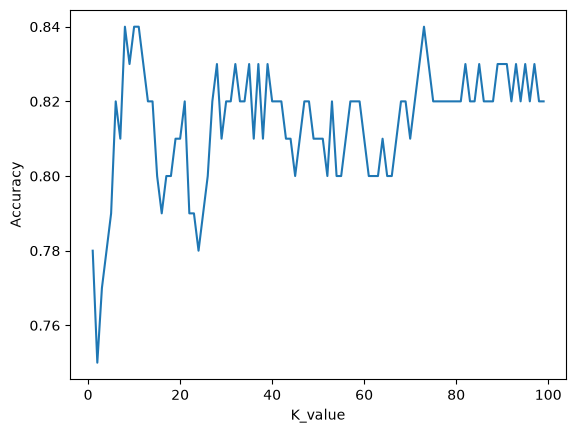

In [4]:
best_k = 1
best_accuracy = 0
accuracy_scores = []

for k in range(1, 100):
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)

    predictions = knn_temp.predict(X_valid_scaled)
    accuracy = accuracy_score(y_true=y_valid, y_pred=predictions)
    accuracy_scores.append(accuracy)
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_k = k

print(f"Best k = {best_k} with accuracy = {best_accuracy}")

import matplotlib.pyplot as plt

plt.plot(range(1, 100), accuracy_scores)
plt.xlabel("K_value")
plt.ylabel("Accuracy")
plt.show()

In [5]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled, y_train)
test_predictions = knn.predict(X_test_scaled)

accuracy = accuracy_score(y_true=y_test, y_pred=test_predictions)

print(f"accuracy = {accuracy}")


accuracy = 0.77


In [7]:
results = pd.DataFrame({
    "x_1": X_test["x_1"],
    "x_2": X_test["x_2"],
    "Original": y_test,
    "Predicted": test_predictions
})

results

,x_1,x_2,Original,Predicted
0,1.637463,4.152545,0.0,0.0
1,1.726565,3.437593,0.0,1.0
2,1.358686,0.757834,0.0,0.0
3,1.620747,4.862745,0.0,1.0
4,0.963280,0.568776,0.0,0.0
...,...,...,...,...
95,2.299773,21.585631,1.0,1.0
96,1.641268,3.810659,1.0,0.0
97,0.574610,3.545178,1.0,0.0
98,1.835419,3.322410,1.0,1.0
